# Chapter 2: Pre-Model Workflow and Data Preprocessing

This notebook covers Chapter 2 of *scikit-learn Cookbook* (3rd Edition, Packt). Real-world data is rarely ready for modeling: it contains missing values, features on very different scales, and categorical text values that models cannot use directly. This chapter covers the preprocessing steps that turn raw data into model-ready input.

**Topics covered:**
- Creating and exploring a dataset
- Handling missing values (imputation)
- Scaling and standardization
- Normalization
- Encoding categorical variables
- Discretization and binarization
- Creating new features (polynomial and custom features)
- Combining everything with `ColumnTransformer` and `Pipeline`

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer
from sklearn.preprocessing import (StandardScaler, MinMaxScaler, RobustScaler,
                                   MaxAbsScaler, Normalizer, OneHotEncoder,
                                   OrdinalEncoder, KBinsDiscretizer, Binarizer,
                                   PolynomialFeatures, FunctionTransformer)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

## 1. Creating a Dataset to Work With

To demonstrate every preprocessing step, we build a small synthetic customer dataset with the typical problems of real data:
- numeric features on very different scales (age, income, number of purchases)
- an outlier in income
- missing values
- categorical features (city, membership level)
- a binary target: whether the customer churned

In [2]:
rng = np.random.default_rng(42)
n = 300

df = pd.DataFrame({
    'age': rng.integers(18, 70, n).astype(float),
    'income': rng.normal(8_000_000, 2_500_000, n).round(-3),
    'purchases': rng.poisson(5, n).astype(float),
    'city': rng.choice(['Bandung', 'Jakarta', 'Surabaya'], n),
    'membership': rng.choice(['Bronze', 'Silver', 'Gold'], n, p=[0.5, 0.3, 0.2]),
})

# Target: churn is more likely for younger customers with few purchases
logit = -0.04 * (df['age'] - 40) - 0.3 * (df['purchases'] - 5)
df['churn'] = (rng.random(n) < 1 / (1 + np.exp(-logit))).astype(int)

# Add an outlier and missing values
df.loc[0, 'income'] = 90_000_000
for col in ['age', 'income', 'purchases']:
    df.loc[rng.choice(n, 20, replace=False), col] = np.nan
df.loc[rng.choice(n, 15, replace=False), 'city'] = np.nan

df.head()

,age,income,purchases,city,membership,churn
0,22.0,90000000.0,5.0,Bandung,Bronze,0
1,NaN,8393000.0,3.0,Jakarta,Silver,1
2,52.0,7603000.0,6.0,Surabaya,Silver,0
3,40.0,5411000.0,3.0,Bandung,Silver,0
4,40.0,3813000.0,NaN,Bandung,Gold,1


In [3]:
print(df.describe().round(2))
print('\nMissing values per column:')
print(df.isna().sum())

          age       income  purchases   churn
count  280.00       280.00     280.00  300.00
mean    43.38   8266492.86       5.06    0.46
std     14.15   5478288.94       2.22    0.50
min     18.00   1583000.00       0.00    0.00
25%     32.00   6255250.00       3.00    0.00
50%     43.00   8014500.00       5.00    0.00
75%     55.25   9462000.00       6.00    1.00
max     69.00  90000000.00      13.00    1.00

Missing values per column:
age           20
income        20
purchases     20
city          15
membership     0
churn          0
dtype: int64


The summary shows the main problems: income is in the millions while purchases are single digits, the maximum income is an extreme outlier, and several columns have missing values. Most scikit-learn models cannot handle missing values or text categories directly, so these must be fixed first.

An important rule before any preprocessing: **split the data first**. All preprocessing parameters (means, medians, categories) must be learned from the training set only, to avoid data leakage.

In [4]:
X = df.drop(columns='churn')
y = df['churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)
print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (225, 5)  Test: (75, 5)


## 2. Handling Missing Values (Imputation)

**Imputation** replaces missing values with estimated ones. Common strategies:
- **SimpleImputer**: replace with the mean, median, most frequent value, or a constant. Fast and simple, but ignores relationships between features. The median is more robust to outliers than the mean.
- **KNNImputer**: replace with the average of the $k$ most similar rows (nearest neighbors). Uses relationships between features, but is slower and sensitive to scaling.
- **IterativeImputer**: models each feature with missing values as a function of the other features, and repeats this in rounds. The most flexible, but also the slowest.

Another useful option is `add_indicator=True`, which adds a column marking where values were missing, since "missingness" itself can carry information.

In [5]:
num_cols = ['age', 'income', 'purchases']

for name, imputer in [('mean', SimpleImputer(strategy='mean')),
                      ('median', SimpleImputer(strategy='median'))]:
    imputer.fit(X_train[num_cols])
    print(f'{name:>6} values learned:', imputer.statistics_.round(1))

  mean values learned: [4.4200000e+01 8.3935472e+06 5.0000000e+00]
median values learned: [4.450e+01 8.104e+06 5.000e+00]


The mean income is pulled upward by the 90 million outlier, while the median is not. This is why the median is usually the safer choice for skewed data or data with outliers.

In [6]:
knn_imp = KNNImputer(n_neighbors=5)
iter_imp = IterativeImputer(random_state=42)

X_knn = knn_imp.fit_transform(X_train[num_cols])
X_iter = iter_imp.fit_transform(X_train[num_cols])

missing_row = X_train[num_cols].isna().any(axis=1).values.argmax()
print('Row with missing values (original):', X_train[num_cols].iloc[missing_row].values)
print('After KNNImputer:                  ', X_knn[missing_row].round(1))
print('After IterativeImputer:            ', X_iter[missing_row].round(1))

Row with missing values (original): [      nan 7.527e+06 4.000e+00]
After KNNImputer:                   [5.040e+01 7.527e+06 4.000e+00]
After IterativeImputer:             [4.450e+01 7.527e+06 4.000e+00]


In [7]:
cat_imp = SimpleImputer(strategy='most_frequent', add_indicator=True)
city_imputed = cat_imp.fit_transform(X_train[['city']])
print('Most frequent city learned:', cat_imp.statistics_)
print(pd.DataFrame(city_imputed, columns=cat_imp.get_feature_names_out()).head())

Most frequent city learned: ['Bandung']
       city missingindicator_city
0  Surabaya                 False
1  Surabaya                 False
2  Surabaya                 False
3  Surabaya                 False
4  Surabaya                 False


KNNImputer and IterativeImputer fill the same missing value with different estimates because they use information from the other features in different ways. For the categorical column, the most frequent city is used, and the extra indicator column records which rows were originally missing.

## 3. Scaling and Standardization

Features measured on very different scales can distort models that rely on distances (KNN, SVM, clustering) or gradient-based optimization (logistic regression, neural networks). scikit-learn provides several scalers:

| Scaler | Formula | When to use |
|:--|:--|:--|
| `StandardScaler` | $z = \frac{x - \mu}{\sigma}$ | General default; assumes roughly normal data |
| `MinMaxScaler` | $x' = \frac{x - x_{min}}{x_{max} - x_{min}}$ | Needs values in a fixed range, e.g. [0, 1] |
| `RobustScaler` | $x' = \frac{x - \text{median}}{IQR}$ | Data with outliers |
| `MaxAbsScaler` | $x' = \frac{x}{\max|x|}$ | Sparse data; keeps zeros as zeros |

Tree-based models (decision trees, random forests) do not need scaling, because they split on thresholds rather than distances.

 StandardScaler: min=-1.15, max=13.80
   MinMaxScaler: min=0.00, max=1.00
   RobustScaler: min=-2.28, max=28.66
   MaxAbsScaler: min=0.02, max=1.00


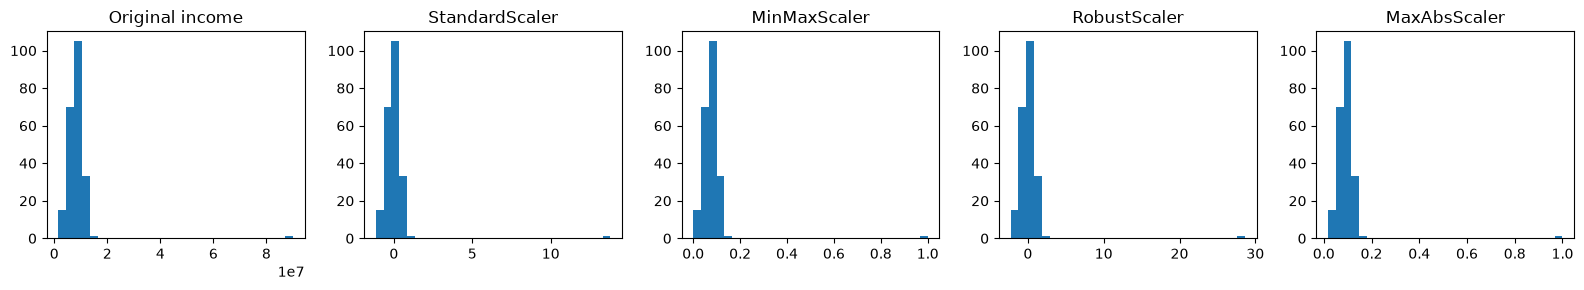

In [8]:
income = SimpleImputer(strategy='median').fit_transform(X_train[['income']])

scalers = {
    'StandardScaler': StandardScaler(),
    'MinMaxScaler': MinMaxScaler(),
    'RobustScaler': RobustScaler(),
    'MaxAbsScaler': MaxAbsScaler(),
}

fig, axes = plt.subplots(1, 5, figsize=(16, 3))
axes[0].hist(income, bins=30)
axes[0].set_title('Original income')

for ax, (name, scaler) in zip(axes[1:], scalers.items()):
    scaled = scaler.fit_transform(income)
    ax.hist(scaled, bins=30)
    ax.set_title(name)
    print(f'{name:>15}: min={scaled.min():.2f}, max={scaled.max():.2f}')

plt.tight_layout()
plt.show()

All scalers keep the shape of the distribution but change its range. Because of the outlier, `MinMaxScaler` and `MaxAbsScaler` squeeze almost all normal customers into a tiny part of the range. `RobustScaler` uses the median and interquartile range, so the outlier has little influence on how the normal values are scaled.

## 4. Normalization

Scaling works **per feature (column)**. **Normalization** with `Normalizer` works **per sample (row)**: it rescales each row so that its vector has length 1:

$$\mathbf{x}' = \frac{\mathbf{x}}{\|\mathbf{x}\|}$$

using the L2 norm $\|\mathbf{x}\|_2 = \sqrt{\sum_j x_j^2}$ by default (or L1, or max). This is useful when only the direction or relative proportions of the features matter, for example in text data or when comparing samples with cosine similarity.

In [9]:
X_small = np.array([[3, 4], [1, 1], [10, 0]], dtype=float)

l2 = Normalizer(norm='l2').fit_transform(X_small)
l1 = Normalizer(norm='l1').fit_transform(X_small)

print('L2-normalized:\n', l2.round(3))
print('Row lengths after L2:', np.linalg.norm(l2, axis=1).round(3))
print('\nL1-normalized:\n', l1.round(3))
print('Row sums after L1:', np.abs(l1).sum(axis=1).round(3))

L2-normalized:
 [[0.6   0.8  ]
 [0.707 0.707]
 [1.    0.   ]]
Row lengths after L2: [1. 1. 1.]

L1-normalized:
 [[0.429 0.571]
 [0.5   0.5  ]
 [1.    0.   ]]
Row sums after L1: [1. 1. 1.]


After L2 normalization every row has length 1, and after L1 normalization the absolute values in every row sum to 1. The row [3, 4] becomes [0.6, 0.8]: its proportions are kept while its size is removed.

## 5. Encoding Categorical Variables

Models need numbers, so text categories must be encoded:
- **OneHotEncoder**: creates one binary column per category. Best for **nominal** categories with no natural order (e.g., city). `handle_unknown='ignore'` prevents errors when the test data contains a category not seen in training.
- **OrdinalEncoder**: maps categories to integers 0, 1, 2, ... Best for **ordinal** categories with a natural order (e.g., Bronze < Silver < Gold). The order should be specified explicitly.

Using ordinal encoding on nominal data would wrongly suggest an order (e.g., Bandung < Jakarta < Surabaya).

In [10]:
city = SimpleImputer(strategy='most_frequent').fit_transform(X_train[['city']])

ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
city_ohe = ohe.fit_transform(city)
print('One-hot columns:', ohe.get_feature_names_out(['city']))
print(city_ohe[:5])

print('\nUnknown category handled:', ohe.transform([['Medan']]))

One-hot columns: ['city_Bandung' 'city_Jakarta' 'city_Surabaya']
[[0. 0. 1.]
 [0. 0. 1.]
 [0. 0. 1.]
 [0. 0. 1.]
 [0. 0. 1.]]

Unknown category handled: [[0. 0. 0.]]


In [11]:
ord_enc = OrdinalEncoder(categories=[['Bronze', 'Silver', 'Gold']])
memb_ord = ord_enc.fit_transform(X_train[['membership']])

print(pd.DataFrame({'membership': X_train['membership'].values[:6],
                    'encoded': memb_ord[:6].ravel()}))

  membership  encoded
0     Bronze      0.0
1     Bronze      0.0
2       Gold      2.0
3     Bronze      0.0
4     Bronze      0.0
5     Silver      1.0


Each city became its own 0/1 column, and an unseen city ("Medan") is encoded as all zeros instead of causing an error. Membership levels were mapped to 0, 1, 2 in their meaningful order, so a model can use the fact that Gold is higher than Silver.

## 6. Discretization and Binarization

Sometimes a continuous feature is more useful as categories:
- **KBinsDiscretizer** splits a feature into $k$ bins. The `strategy` can be `'uniform'` (equal-width bins), `'quantile'` (equal number of samples per bin), or `'kmeans'` (bins based on clustering).
- **Binarizer** turns values into 0 or 1 based on a threshold.

Discretization can help linear models capture nonlinear effects (e.g., churn risk being different for age groups), at the cost of losing detail within each bin.

In [12]:
age = SimpleImputer(strategy='median').fit_transform(X_train[['age']])

kbins = KBinsDiscretizer(n_bins=4, encode='ordinal', strategy='quantile')
age_bins = kbins.fit_transform(age)
print('Bin edges for age:', kbins.bin_edges_[0].round(1))
print('Customers per bin:', np.bincount(age_bins.ravel().astype(int)))

purchases = SimpleImputer(strategy='median').fit_transform(X_train[['purchases']])
active = Binarizer(threshold=4).fit_transform(purchases)
print('\nShare of "active" customers (more than 4 purchases):', active.mean().round(3))

Bin edges for age: [18.  35.  44.5 55.  69. ]
Customers per bin: [56 47 63 59]

Share of "active" customers (more than 4 purchases): 0.573


With the `'quantile'` strategy, each age bin contains roughly the same number of customers. The binarizer turns the number of purchases into a simple active/inactive flag.

## 7. Creating New Features

**Feature engineering** creates new features that make patterns easier for a model to learn.
- **PolynomialFeatures** adds squared terms and interaction terms. For two features $x_1, x_2$ with degree 2, it produces $1, x_1, x_2, x_1^2, x_1 x_2, x_2^2$. This lets linear models fit curved relationships and interactions.
- **FunctionTransformer** wraps any function (e.g., a log transform) as a transformer, so it can be used inside pipelines. A log transform such as $\log(1 + x)$ reduces right skew in features like income.

In [13]:
X_two = np.array([[1, 2], [3, 4]], dtype=float)
poly = PolynomialFeatures(degree=2)
print('Feature names:', poly.fit(X_two).get_feature_names_out(['x1', 'x2']))
print(poly.transform(X_two))

Feature names: ['1' 'x1' 'x2' 'x1^2' 'x1 x2' 'x2^2']
[[ 1.  1.  2.  1.  2.  4.]
 [ 1.  3.  4.  9. 12. 16.]]


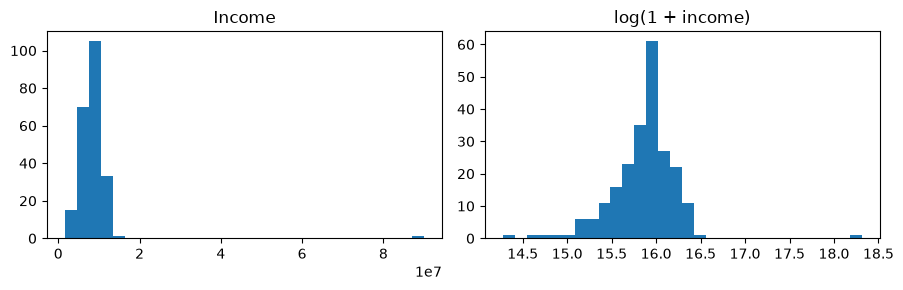

In [14]:
log_tf = FunctionTransformer(np.log1p, feature_names_out='one-to-one')
income_log = log_tf.fit_transform(income)

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].hist(income, bins=30)
axes[0].set_title('Income')
axes[1].hist(income_log, bins=30)
axes[1].set_title('log(1 + income)')
plt.tight_layout()
plt.show()

PolynomialFeatures expanded two features into six, including the interaction $x_1 x_2$. The log transform compresses large income values, which makes the outlier much less extreme relative to the rest of the data.

## 8. Putting It All Together: ColumnTransformer and Pipeline

Different columns need different preprocessing. **ColumnTransformer** applies a separate pipeline to each group of columns and combines the results. Wrapping it in a **Pipeline** with a model gives one object that:
- learns all preprocessing parameters from training data only
- applies exactly the same steps to test data
- can be cross-validated, tuned, and saved as a whole

In [15]:
numeric_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale', RobustScaler()),
])
nominal_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])
ordinal_pipe = Pipeline([
    ('encode', OrdinalEncoder(categories=[['Bronze', 'Silver', 'Gold']])),
])

preprocess = ColumnTransformer([
    ('num', numeric_pipe, ['age', 'income', 'purchases']),
    ('city', nominal_pipe, ['city']),
    ('memb', ordinal_pipe, ['membership']),
])
preprocess.set_output(transform='pandas')

X_train_ready = preprocess.fit_transform(X_train)
print('Missing values after preprocessing:', X_train_ready.isna().sum().sum())
X_train_ready.head()

Missing values after preprocessing: 0


,num__age,num__income,num__purchases,city__city_Bandung,city__city_Jakarta,city__city_Surabaya,memb__membership
269,0.175,1.124913,0.666667,0.0,0.0,1.0,0.0
87,-0.525,-0.608467,0.333333,0.0,0.0,1.0,0.0
151,-0.625,0.250525,-0.666667,0.0,0.0,1.0,2.0
152,1.025,1.474458,1.000000,0.0,0.0,1.0,0.0
292,0.000,-0.201889,-0.333333,0.0,0.0,1.0,0.0


In [16]:
model = Pipeline([
    ('preprocess', preprocess),
    ('classifier', LogisticRegression(max_iter=1000)),
])
model.fit(X_train, y_train)

print(f'Training accuracy: {model.score(X_train, y_train):.3f}')
print(f'Test accuracy:     {model.score(X_test, y_test):.3f}')

Training accuracy: 0.618
Test accuracy:     0.640


The ColumnTransformer turned the raw data (with missing values, outliers, and text) into a clean numeric table with readable column names. The full pipeline goes from raw data to predictions in a single `fit()` call, and the test set is processed with the parameters learned from training only, so there is no data leakage.

## Chapter Summary

- Always **split the data before preprocessing**, and learn all preprocessing parameters from the training set only.
- **Imputation** fills missing values: `SimpleImputer` (mean, median, most frequent) is fast, while `KNNImputer` and `IterativeImputer` use relationships between features. The median is robust to outliers.
- **Scaling** works per feature: `StandardScaler` is the default, `MinMaxScaler` maps to a fixed range, `RobustScaler` handles outliers, and `MaxAbsScaler` suits sparse data. Tree-based models do not need scaling.
- **Normalization** with `Normalizer` works per sample, giving each row unit length.
- **Encoding**: `OneHotEncoder` for nominal categories, `OrdinalEncoder` with an explicit order for ordinal categories.
- **Discretization** (`KBinsDiscretizer`) and **binarization** (`Binarizer`) convert continuous values into categories or flags.
- **Feature engineering** with `PolynomialFeatures` and `FunctionTransformer` helps models capture nonlinear patterns and reduces skew.
- **ColumnTransformer** plus **Pipeline** combine all these steps into one leak-free, reusable workflow.